In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from catboost import CatBoostRegressor
import numpy as np
import seaborn as sns
from scipy import stats
import string
import emoji
import nltk
import pymorphy3
from nltk.corpus import stopwords 
# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (16, 10)

## Общий анализ и обработка данных

In [2]:
df = pd.read_csv('vk_zhukov_extended.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         300 non-null    int64
 1   date       300 non-null    int64
 2   text       263 non-null    str  
 3   has_text   300 non-null    int64
 4   has_photo  300 non-null    int64
 5   has_video  300 non-null    int64
 6   likes      300 non-null    int64
 7   comments   300 non-null    int64
 8   reposts    300 non-null    int64
 9   views      300 non-null    int64
dtypes: int64(9), str(1)
memory usage: 23.6 KB


In [4]:
df.head()

,id,date,text,has_text,has_photo,has_video,likes,comments,reposts,views
0,194236,1755512569,"Ребят, а вы в чем-то считаете себя профи? Вот ...",1,0,1,2066,243,51,143208
1,194177,1753811557,"Честно скажу, столько лет я в музыке, в конкур...",1,0,1,529,41,11,82558
2,194080,1753106688,"А у нас теперь ферма🌱 Не шутка, не образ, не д...",1,0,1,4301,111,169,101445
3,194029,1752075652,NaN,0,0,1,1965,59,103,79738
4,193696,1747826165,"Друзья!\nНаш концерт в Санкт-Петербурге, котор...",1,1,0,454,100,86,62706


In [5]:
df['text'] = df['text'].fillna('')
df['text'] = df['text'].str.replace('\n', ' ')

In [6]:
# Перевод даты из секунд в timestamp
df['date'] = pd.to_datetime(df['date'], unit='s')

In [7]:
# Выделение временных признаков
df['hour'] = df['date'].dt.hour
df['day_of_week'] = df['date'].dt.day_name() 
df['is_weekend'] = df['date'].dt.weekday.isin([5, 6]).astype(int)
df["month_num"] = df["date"].dt.month


Для ВК лучше всего рассчитать общую метрику, которая будет отражать вовлеченность в целом,а именно Engagement Rate:

1. ER view (Вовлеченность по охвату): Показывает качество самого контента.
$$ER_{view} = \frac{\text{likes} + \text{comments} + \text{reposts}}{\text{views}} \times 100\%$$


In [8]:
# Расчет метрики вовлеченности (ER view). Добавим +1 к views на случай нулевых охватов, чтобы избежать деления на ноль
df['er_view'] = ((df['likes'] + df['comments'] + df['reposts']) / (df['views'] + 1)) * 100


In [9]:
df.describe()

,id,date,has_text,has_photo,has_video,likes,comments,reposts,views,hour,is_weekend,month_num,er_view
count,300.000000,300,300.000000,300.00000,300.000000,300.000000,300.00000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,183116.633333,2020-10-05 12:52:15,0.876667,0.54000,0.203333,1187.023333,56.27000,27.346667,56634.223333,12.620000,0.220000,6.236667,2.253713
min,174250.000000,2019-05-09 00:26:34,0.000000,0.00000,0.000000,66.000000,0.00000,0.000000,7709.000000,0.000000,0.000000,1.000000,0.242626
25%,178562.750000,2019-07-05 05:30:49,1.000000,0.00000,0.000000,384.500000,16.00000,6.000000,24765.500000,9.000000,0.000000,5.000000,1.296376
50%,182915.000000,2019-09-29 21:29:56,1.000000,1.00000,0.000000,770.500000,30.50000,12.000000,35184.000000,12.000000,0.000000,6.000000,2.057949
75%,187006.250000,2021-09-20 08:09:34,1.000000,1.00000,0.000000,1366.250000,58.00000,26.250000,62241.000000,17.000000,0.000000,8.000000,2.938271
max,194236.000000,2025-08-18 10:22:49,1.000000,1.00000,1.000000,24185.000000,870.00000,533.000000,469290.000000,23.000000,1.000000,12.000000,7.999811
std,5318.162701,NaN,0.329369,0.49923,0.403151,1770.823759,94.35394,51.335279,60212.018232,5.227494,0.414938,2.665396,1.225175


Посмотрю, распределение метрик, пригодится при проверке гипотез с помощью статистических тестов

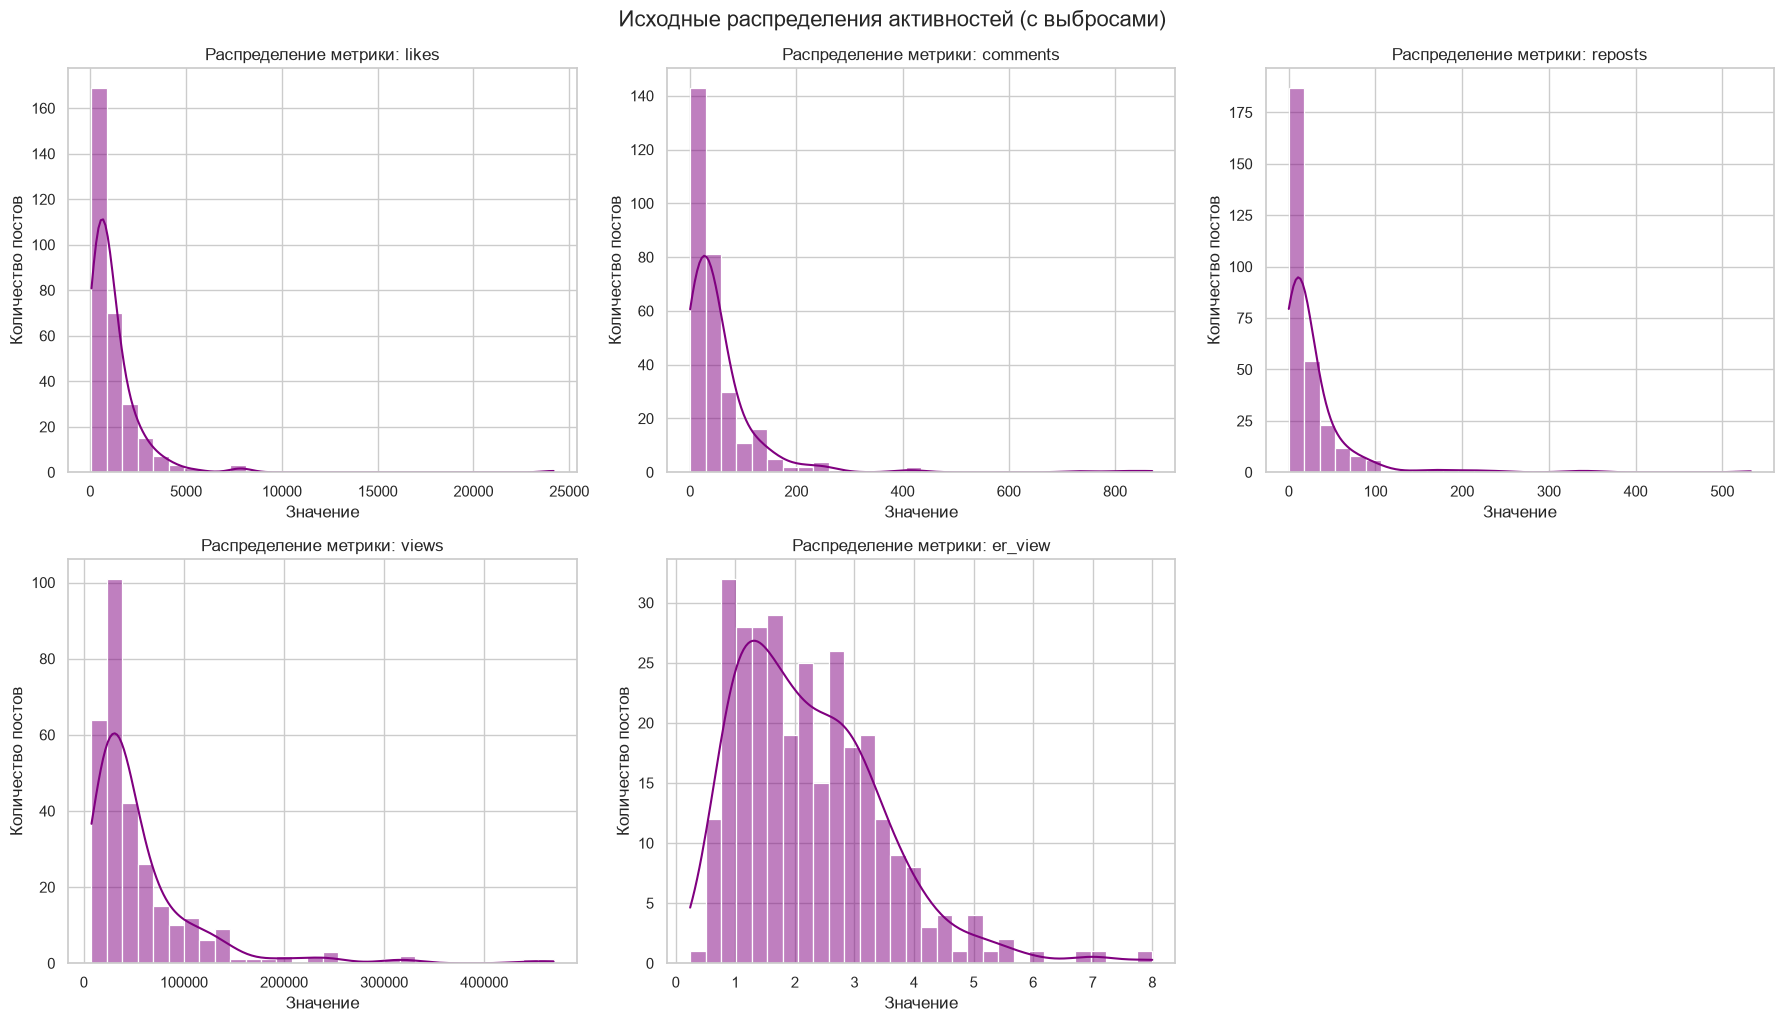

In [11]:

# Список метрик для визуализации
metrics = ["likes", "comments", "reposts", "views", "er_view"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, metric in enumerate(metrics):
    sns.histplot(
        data=df, x=metric, kde=True, ax=axes[i], color="purple", bins=30
    )
    axes[i].set_title(f"Распределение метрики: {metric}")
    axes[i].set_xlabel("Значение")
    axes[i].set_ylabel("Количество постов")

# Удаляем лишний шестой пустой мини-график
fig.delaxes(axes[-1])
plt.tight_layout()
plt.suptitle(
    "Исходные распределения активностей (с выбросами)", y=1.02, fontsize=16
)
plt.show()


* Просмотры (views): Медиана — около 35 тыс., а максимум — 469 тыс. Это значит, что есть единичные супер-вирусные посты, которые улетают в умную ленту ВК.
* Лайки (likes): Среднее значение составляет 1187, но медиана всего 770. Максимум - 24 185 лайков.


Распределения сильно скошены вправо (высокое стандартное отклонение std). Обычная линейная корреляция Пирсона здесь покажет искаженные результаты. Нам нужно будет использовать ранговую корреляцию Спирмена либо логарифмировать эти метрики перед анализом.


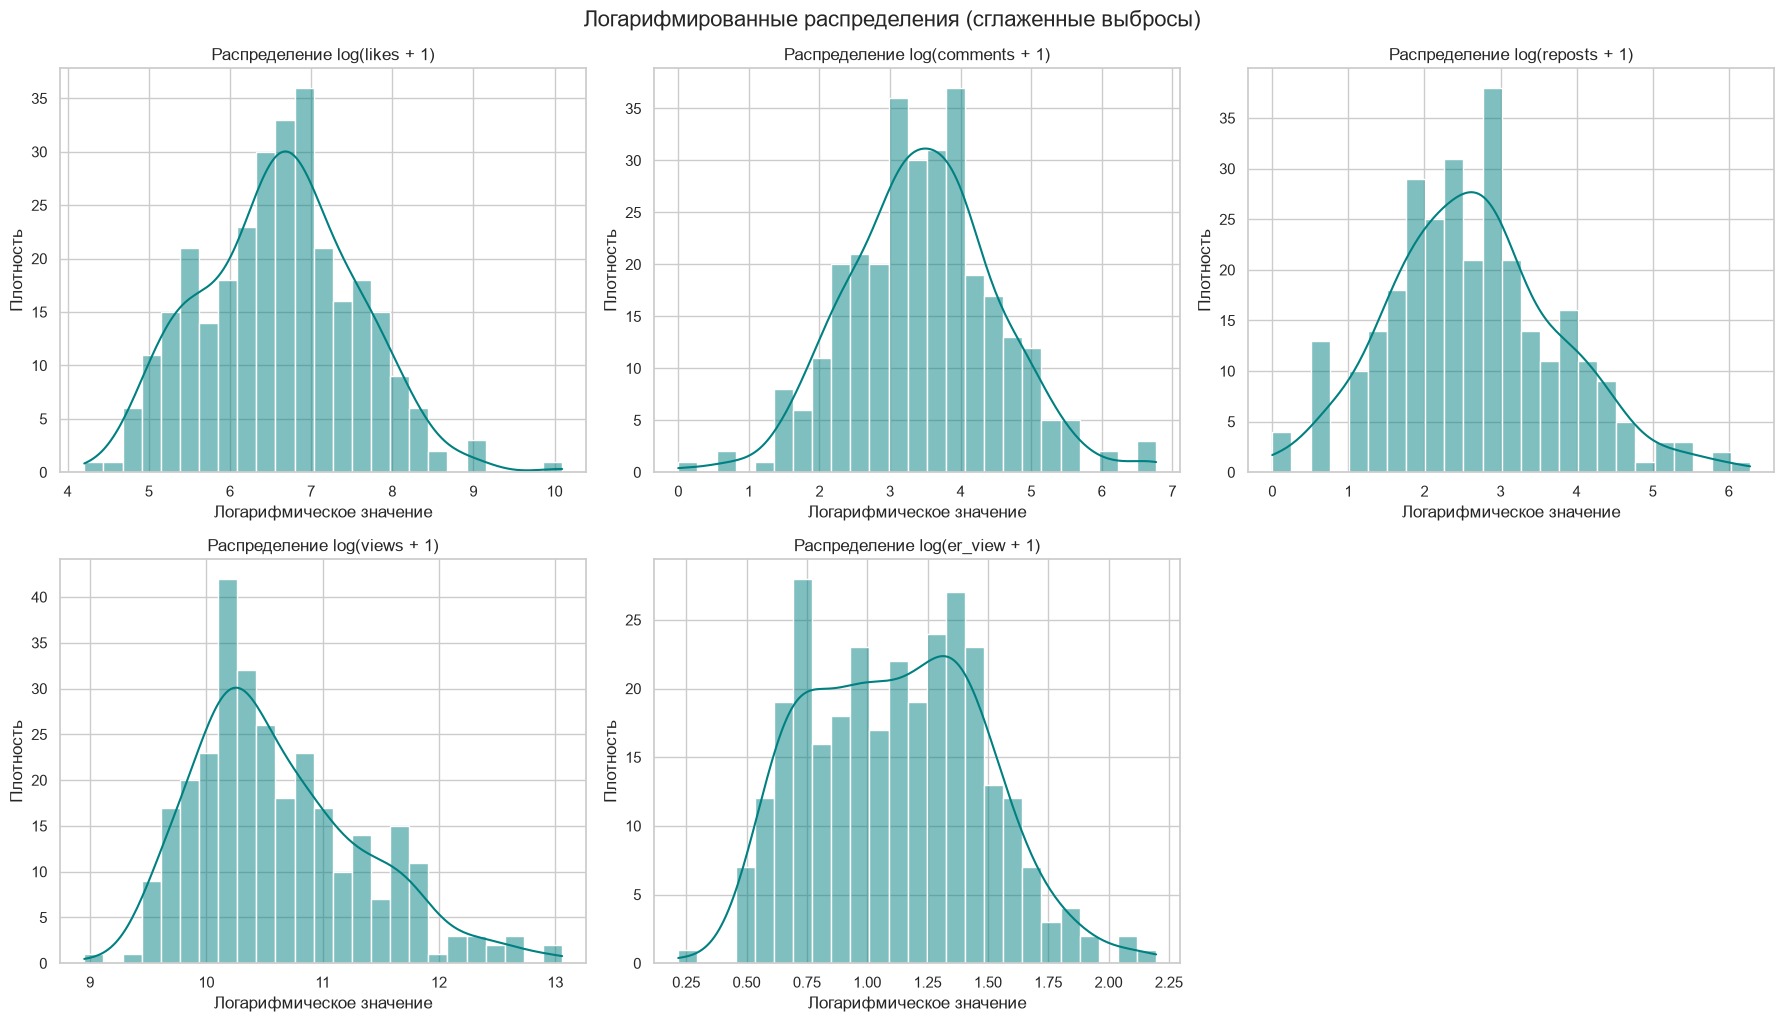

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    # Добавляем +1, чтобы не было log(0) для комментов или репостов
    sns.histplot(
        data=df,
        x=np.log1p(df[metric]),
        kde=True,
        ax=axes[i],
        color="teal",
        bins=25,
    )
    axes[i].set_title(f"Распределение log({metric} + 1)")
    axes[i].set_xlabel("Логарифмическое значение")
    axes[i].set_ylabel("Плотность")

fig.delaxes(axes[-1])
plt.tight_layout()
plt.suptitle(
    "Логарифмированные распределения (сглаженные выбросы)",
    y=1.02,
    fontsize=16,
)
plt.show()

Поскольку исходные метрики сильно искажены выбросами, использовать среднее  на сырых данных будет ошибкой (один пост-миллионник смажет всю картину месяца). Поэтому целесообразнее использовать медиану (median), так как она устойчива к выбросам.

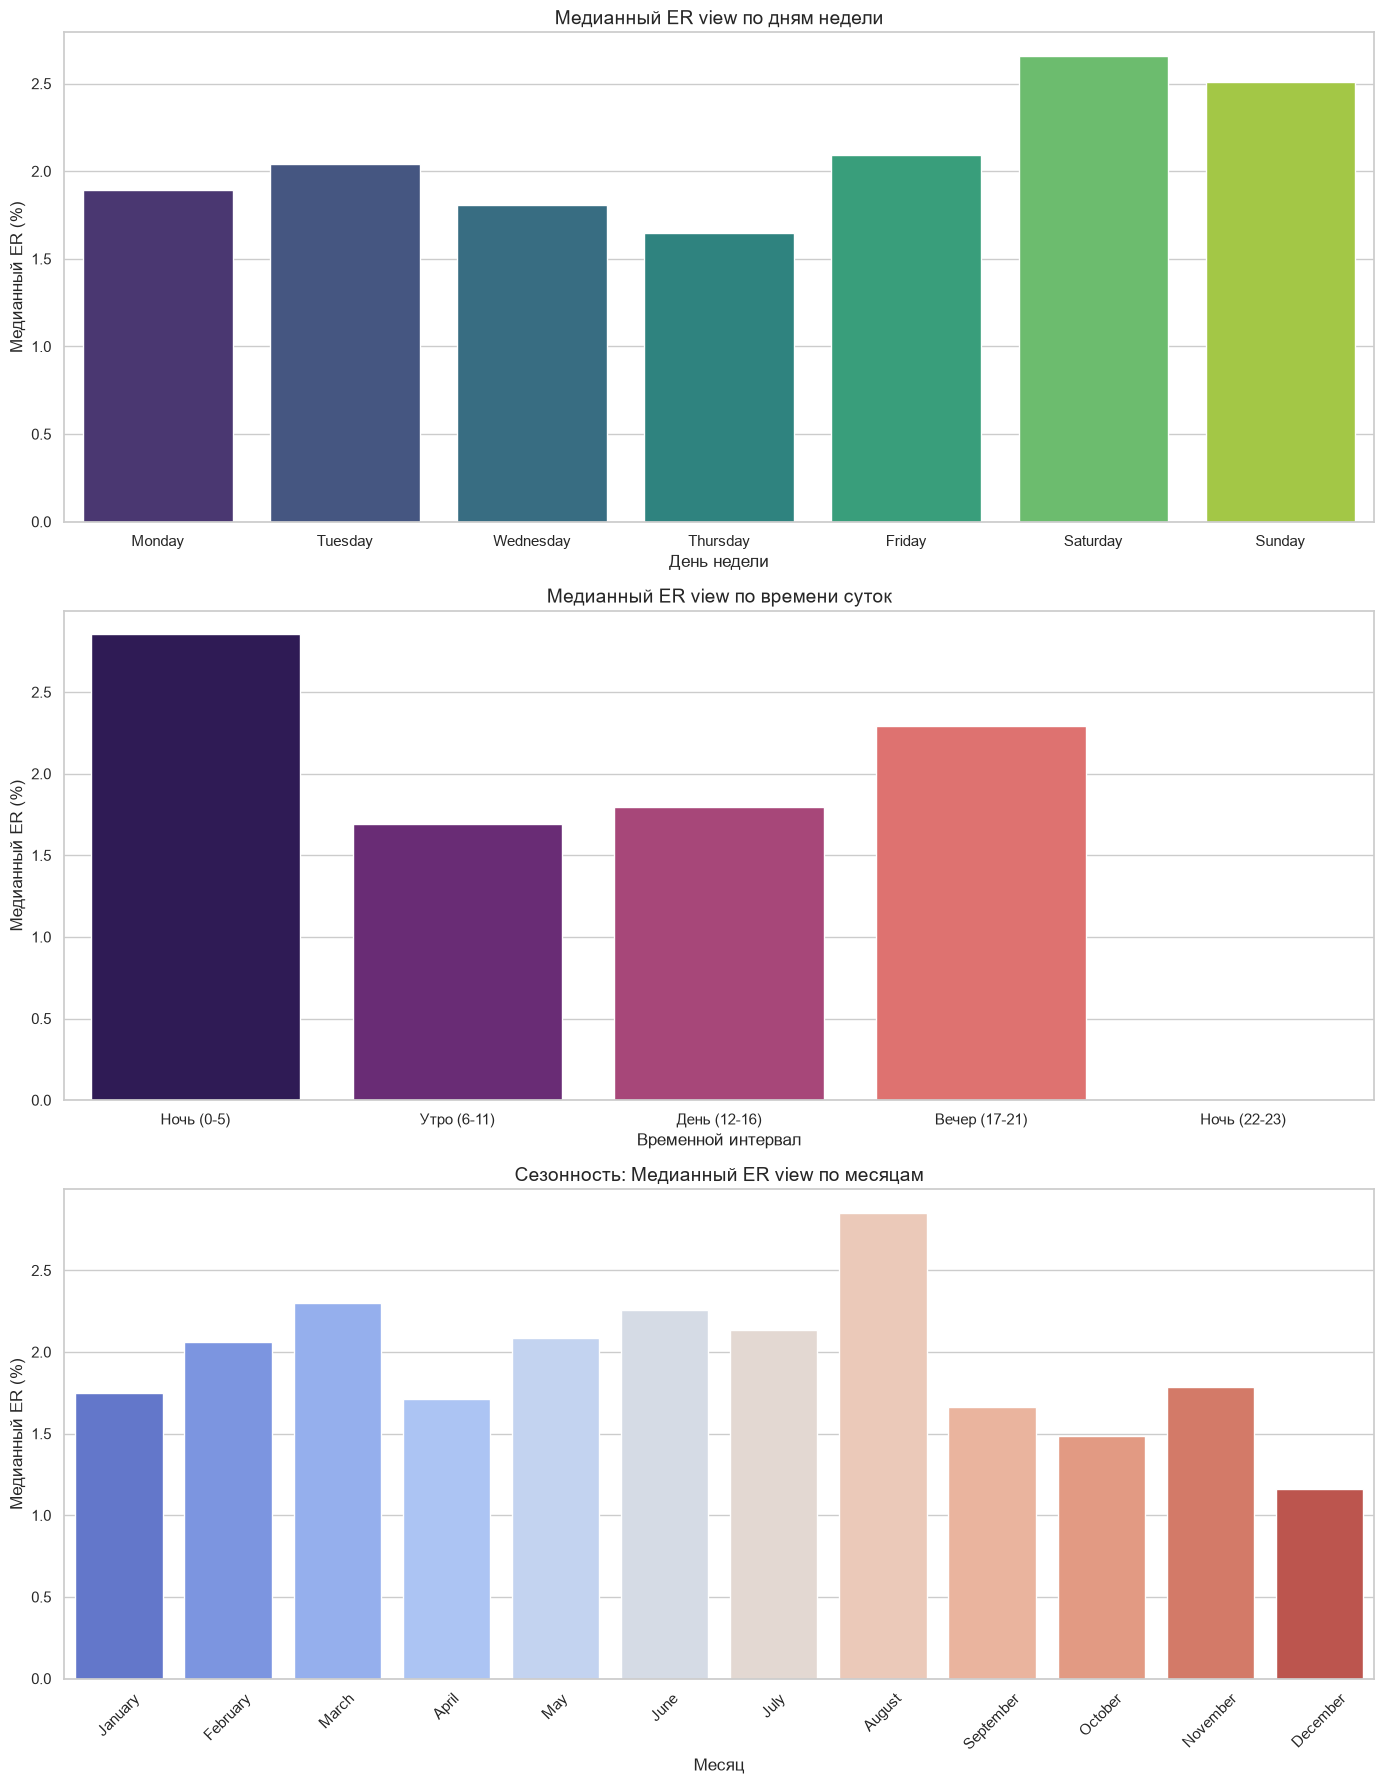

In [13]:
# Подготовка временных признаков (если еще не созданы)
df["month"] = df["date"].dt.strftime("%B")  # Названия месяцев
df["hour_group"] = pd.cut(
    df["hour"],
    bins=[-1, 5, 11, 16, 21, 24],
    labels=["Ночь (0-5)", "Утро (6-11)", "День (12-16)", "Вечер (17-21)", "Ночь (22-23)"],
)
# Объединим ночные категории 
df["hour_group"] = df["hour_group"].replace("Ночь (22-23)", "Ночь (0-5)")

# Сортировка для графиков
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
months_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]
# Отфильтруем только те месяцы, которые физически есть в данных
actual_months = [m for m in months_order if m in df["month"].unique()]

fig, axes = plt.subplots(3, 1, figsize=(14, 18))

# 1. Зависимость от Дня Недели
sns.barplot(
    data=df,
    x="day_of_week",
    y="er_view",
    order=days_order,
    estimator=np.median,
    errorbar=None,
    ax=axes[0],
    palette="viridis",
)
axes[0].set_title(
    "Медианный ER view по дням недели", fontsize=14
)
axes[0].set_xlabel("День недели")
axes[0].set_ylabel("Медианный ER (%)")

# 2. Зависимость от Времени Суток
sns.barplot(
    data=df,
    x="hour_group",
    y="er_view",
    estimator=np.median,
    errorbar=None,
    ax=axes[1],
    palette="magma",
)
axes[1].set_title("Медианный ER view по времени суток", fontsize=14)
axes[1].set_xlabel("Временной интервал")
axes[1].set_ylabel("Медианный ER (%)")

# 3. Сезонность по Месяцам
sns.barplot(
    data=df,
    x="month",
    y="er_view",
    order=actual_months,
    estimator=np.median,
    errorbar=None,
    ax=axes[2],
    palette="coolwarm",
)
axes[2].set_title("Сезонность: Медианный ER view по месяцам", fontsize=14)
axes[2].set_xlabel("Месяц")
axes[2].set_ylabel("Медианный ER (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Выводы:

1) Вечером и особенно ночью фиксируется максимальный ER view, скорее всего из-за того, что вечером появляется свободное время,у людей есть время на вовлеченность.
2) По выходным вовлеченность выше, чем в будни по тем же причинам.
3) Ярко выраженная сезонность (Март, Июнь-Июль и взрывной Август)

In [14]:
df['is_weekend'] = df['date'].dt.weekday.isin([5, 6]).astype(int)


# Если час публикации >= 17 или час <= 5, то это вечер/ночь (1), иначе день/утро (0)
df['is_night_evening'] = ((df['hour'] >= 17) | (df['hour'] <= 5)).astype(int)

# Выделяем пиковые месяцы сезонности (Март, Июнь, Июль, Август)
df['is_peak_month'] = df['date'].dt.month.isin([3, 6, 7, 8]).astype(int)

In [15]:
# Применяем log1p (натуральный логарифм от x + 1), чтобы безопасно обработать нули в коммментариях и репостах
df['log_likes'] = np.log1p(df['likes'])
df['log_comments'] = np.log1p(df['comments'])
df['log_reposts'] = np.log1p(df['reposts'])
df['log_views'] = np.log1p(df['views'])
df['log_er_view'] = np.log1p(df['er_view'])

## Работа с текстом

#### Базовые паттерны

Чтобы обработать текст, мной были выделены несколько новых признаков, которые позволят выявить взаимосвязь текста с активностью пользователей на странице:

- длина текста 
- наличие эмодзи, благодаря которым количество реакции может увеличиться
- наличие слов написанные капсолоком - индикатор агрессивного маркетинга и привлечения внимания (например, анонсы городов или туров)

Однако, длина текста и его регистр определяют лишь форму подачи контента. Для глубокого понимания взаимосвязей необходимо проанализировать смысловое содержание публикаций, т.е. классифицировать посты по ключевым бизнес-направлениям артиста без субъективных догадок.

Для этого мной будет применятся инструмент **лемматизации** с помощью библиотеки `pymorphy3` и предобработку текста:
1. **Фильтрация стоп-слов:** С помощью библиотечных списков `nltk` из текста удаляются предлоги, союзы и местоимения, не несущие смысловой нагрузки.
2. **Нормализация токенов:** Каждое значащее слово приводится к своей начальной форме (единственное число, именительный падеж для существительных; инфинитив для глаголов). 

В результате мы сформируем очищенную колонку `text_lemmatized`, на основе которой проведем частотный анализ слов-маркеров контента.

In [ ]:
def make_seq(text):
   """Функция, вспомогательная для других функций 
   (длина списка (кол-во слов), булевый признак, если доля текста, 
   написанная капсом выше 20%) возвращает список"""
   text =''.join([item for item in text if item not in string.punctuation])
   seq = text.split()
   return seq

def count_word(text):
   """Кол-во слов в посте
   возвращает длину списку"""
   text = make_seq(text)
   return len(text)
   
def detected_caps_lock(text):
   """Функция возвращает булевый флаг
   взависимости от превышение доли в 20% текста, 
   написанного капслоком"""
   text = make_seq(text)
   up_text = [item for item in text if item.isupper()]
   return True if text and (len(up_text)*100 / len(text)) >= 10 else False           


In [18]:
#рассчитываем длину текста
df["word_count"] = df["text"].apply(count_word)
#применю функции
df['up_text'] = df['text'].apply(detected_caps_lock)
df['emoji'] = df['text'].apply(lambda x:
    True if sum(1 for char in x if char in emoji.EMOJI_DATA)>0 else False)

#### Лемматизация

In [20]:
# Скачиваем стоп-слова для русского языка (нужно запустить один раз)
nltk.download("stopwords",quiet=True)

# Инициализируем лемматизатор и список стоп-словарей
morph = pymorphy3.MorphAnalyzer()
russian_stopwords = stopwords.words("russian")
# Можно добавить кастомные стоп-слова, которые часто встречаются, но не несут смысла (например, "сергей", "жуков")
additional_stopwords = ["это", "наш", "свой", "который", "весь"]
russian_stopwords.extend(additional_stopwords)


def preprocess_and_lemmatize(text):
    if not isinstance(text, str) or not text:
        return ""

    # 1. Приведение к нижнему регистру и удаление пунктуации (как в твоем методе)
    text_lower = text.lower()
    text_no_punc = "".join(
        [char for char in text_lower if char not in string.punctuation]
    )

    # 2. Разбиение на слова
    words = text_no_punc.split()

    # 3. Лемматизация + фильтрация стоп-слов и коротких символов
    lemmatized_words = []
    for word in words:
        if word not in russian_stopwords and len(word) > 2:
            # Приводим слово к нормальной форме (номинатив, единственное число)
            lemma = morph.parse(word)[0].normal_form
            # Проверяем еще раз, вдруг лемма оказалась стоп-словом
            if lemma not in russian_stopwords:
                lemmatized_words.append(lemma)

    # Возвращаем очищенную строку из лемм, разделенных пробелом
    return " ".join(lemmatized_words)

# Применяем лемматизацию к датасету
df["text_lemmatized"] = df["text"].apply(preprocess_and_lemmatize)

In [ ]:
#можно посмотреть частотность слов по лемматизации
pd.Series(' '.join(df['text_lemmatized']).split()).value_counts().head(15)

концерт      80
ждать        73
вверх        70
ваш          62
друг         61
рукивверх    61
бар          60
самый        59
новый        58
день         51
год          47
москва       46
спасибо      46
рука         45
«рука        45
Name: count, dtype: int64

In [22]:
#выделим наиболее популярные в отдельные признаки
df["cat_concert"] = (
    df["text_lemmatized"]
    .str.contains(
        r"концерт|шоу|тур|билет|москва|стадион|спасибо", regex=True
    )
    .astype(int)
)
df["cat_bar"] = (
    df["text_lemmatized"].str.contains(r"бар", regex=True).astype(int)
)
df["cat_nostalgia_brand"] = (
    df["text_lemmatized"]
    .str.contains(r"рукивверх|вверх|песня|трек|клип|альбом", regex=True)
    .astype(int)
)
df["cat_personal"] = (
    df["text_lemmatized"]
    .str.contains(r"друг|семья|ребенок|жена|день|год|праздник", regex=True)
    .astype(int)
)


In [23]:
# Проверю объем получившихся категорий
print("Распределение по категориям:")
for col in ["cat_concert", "cat_bar", "cat_nostalgia_brand", "cat_personal"]:
    print(f"{col}: {df[col].sum()} постов")

Распределение по категориям:
cat_concert: 105 постов
cat_bar: 51 постов
cat_nostalgia_brand: 127 постов
cat_personal: 121 постов


Выделенные слова-лидеры — *концерт (80)*, *ждать (73)*, *вверх (70)* и *бар (60)* — позволили математически точно распределить массив данных по 4 независимым бизнес-категориям контента:

* **Концертная деятельность (`cat_concert`) — 105 постов.** Публикации, связанные с гастролями, стадионными шоу и продажей билетов.
* **Ресторанный бизнес (`cat_bar`) — 51 пост.** Коммерческий контент, возможно продвигающий Бар».
* **Музыкальное наследие и бренд (`cat_nostalgia_brand`) — 127 постов.** Анонсы треков, клипов, альбомов и триггеры ностальгии по эпохе 90-х.
* **Личный контент (`cat_personal`) — 121 пост.** Посты о семье, детях, личных праздниках и неформальные обращения к аудитории.


## Корреляционный анализ

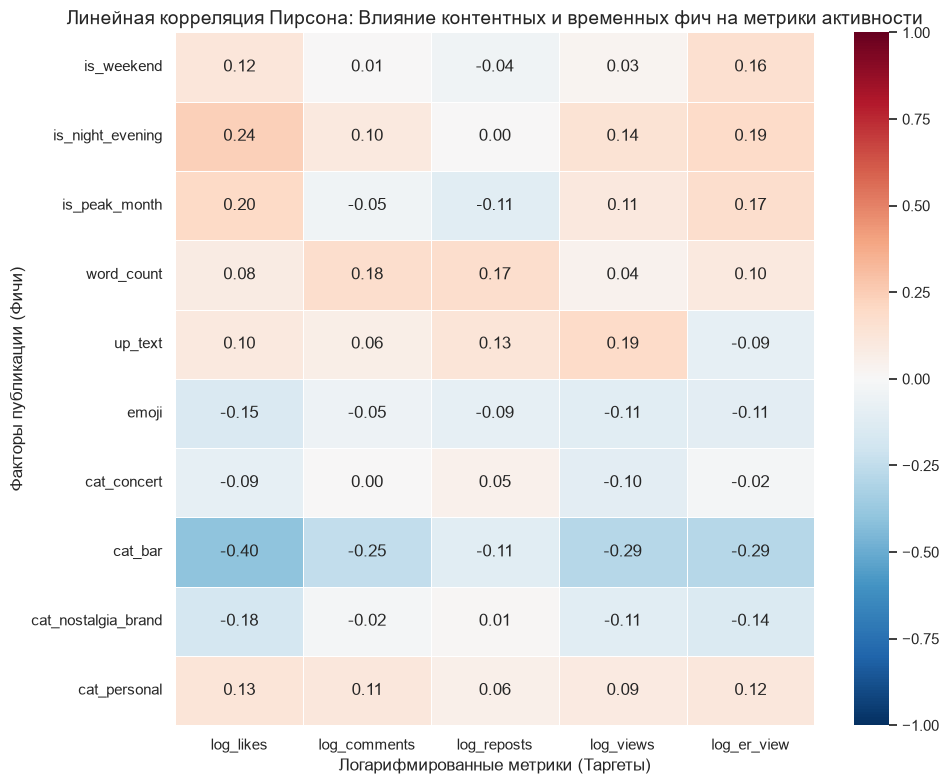

In [24]:
# 1. Формируем списки признаков для прямоугольной матрицы
features = [
    "is_weekend",
    "is_night_evening",
    "is_peak_month",
    "word_count",
    "up_text",
    "emoji",
    "cat_concert",
    "cat_bar",
    "cat_nostalgia_brand",
    "cat_personal",
]

targets = ["log_likes", "log_comments", "log_reposts", "log_views", "log_er_view"]

# 2. Расчет полной матрицы корреляции Пирсона
full_corr = df[features + targets].corr(method="pearson")

# Вырезаем только пересечения фич с таргетами
rectangular_corr = full_corr.loc[features, targets]

# 3. Визуализация тепловой карты
plt.figure(figsize=(10, 8))
sns.heatmap(
    rectangular_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",  # Красный — положительная корреляция, синий — отрицательная
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=False,
)

plt.title(
    "Линейная корреляция Пирсона: Влияние контентных и временных фич на метрики активности",
    fontsize=14,
)
plt.ylabel("Факторы публикации (Фичи)")
plt.xlabel("Логарифмированные метрики (Таргеты)")
plt.tight_layout()
plt.show()

1. Временные признаки больше всего коррелируют с метриками вовлеченности:
	- is_night_evening и log_er_view (0.19): Это самая сильная положительная корреляция среди всех внешних факторов! Публикация вечером и ночью линейно связана с ростом ER. При этом растет и log_views (0.14). Ночные и вечерние посты Сергея получают больше внимания и охватов.
	- is_peak_month (0.17) и is_weekend (0.16): Пиковые месяцы (март, июнь-август) и выходные дни имеют устойчивую положительную связь с ростом вовлеченности. Математика подтверждает сезонный и недельный триггер аудитории.
2. Посты про бар, возможно имеется ввиду реклама бара (cat_bar) имеет отрицательную корреляцию с вовлеченностью.

	- cat_nostalgia_brand (-0.14): Как ни странно, чистые посты про бренд/музыку тоже имеют легкий негативный тренд по ER, в то время как cat_personal (0.12) — единственный контентный кластер с устойчивым плюсом. Людей можно сказать привлекает контент про личную жизнь, семью Сергея Жукова.
3. Анализ формы текста: Разрыв между Охватом и Лайками (up_text):
	- up_text (Капс) и log_views (0.19): Капслок отлично привлекает внимание алгоритмов умной ленты и случайных пользователей — просмотры растут.
	- up_text и log_er_view (-0.09): Но как только дело доходит до реальной вовлеченности лояльных фанатов, капс уходит в минус. Он дает охваты, но снижает качество отклика.
	- emoji (-0.11): Удивительно, но сам факт наличия эмодзи имеет небольшую отрицательную корреляцию со всеми метриками вовлеченности.


## Проверка гипотез

Гипотеза №1: Влияние времени суток (День/Утро vs Вечер/Ночь) на вовлеченность (er_view)

Мы хотим доказать или опровергнуть, что посты, опубликованные в вечернее и ночное время, показывают качественно иной уровень вовлеченности аудитории, чем публикации, сделанные утром или днем.

- Нулевая гипотеза $H_{0}$: Средние значения log_er_view в группах «День/Утро» и «Вечер/Ночь» равны. Время публикации не влияет на вовлеченность.
- Альтернативная гипотеза $H_{1}$: Средние значения log_er_view в этих группах значимо различаются.

In [25]:
import numpy as np
import pandas as pd
from scipy import stats


def test_hypothesis_pipeline(data, factor_col, target_log_col, target_raw_col):
    """Строгий статистический пайплайн для проверки бинарных гипотез."""
    print(f"\n" + "=" * 60)
    print(f"ГИПОТЕЗА: Влияние фактора '{factor_col}' на вовлеченность")
    print("=" * 60)

    # 1. Разделение на группы
    group_0 = data[data[factor_col] == 0][target_log_col]
    group_1 = data[data[factor_col] == 1][target_log_col]

    n0, n1 = len(group_0), len(group_1)
    print(f"Размеры выборок: Группа [0] = {n0} постов, Группа [1] = {n1} постов")

    if n0 < 3 or n1 < 3:
        print("-> Критическая ошибка: Недостаточно данных в одной из групп!")
        return

    # 2. Проверка нормальности (Тест Шапиро-Уилка)
    shapiro_0_stat, shapiro_0_p = stats.shapiro(group_0)
    shapiro_1_stat, shapiro_1_p = stats.shapiro(group_1)

    print(f"\n[Шаг 1] Проверка на нормальность (Шапиро-Уилка):")
    print(f"  Группа: p-value = {shapiro_0_p:.5f}")
    print(f"  Группа: p-value = {shapiro_1_p:.5f}")

    both_normal = (shapiro_0_p > 0.05) and (shapiro_1_p > 0.05)

    # 3. Выбор статистического критерия
    if both_normal:
        print("-> Обе группы распределены нормально. Проверяем дисперсию...")

        # Проверка равенства дисперсий (Тест Левена)
        levene_stat, levene_p = stats.levene(group_0, group_1)
        print(f"\n[Шаг 2] Проверка равенства дисперсий (Левена):")
        print(f"  p-value = {levene_p:.5f}")

        equal_vars = parity_p > 0.05
        if equal_vars:
            print(
                "-> Дисперсии равны. Применяем классический t-критерий Стьюдента."
            )
        else:
            print("-> Дисперсии НЕ равны. Применяем t-критерий Уэлча.")

        # Финальный параметрический тест
        stat, p_val = stats.ttest_ind(group_1, group_0, equal_var=equal_vars)
        test_name = (
            "t-критерий Стьюдента" if equal_vars else "t-критерий Уэлча"
        )

    else:
        print(
            "-> [Внимание] Нормальность нарушена. Применяем непараметрический U-критерий Манна-Уитни."
        )
        stat, p_val = stats.mannwhitneyu(
            group_1, group_0, alternative="two-sided"
        )
        test_name = "U-критерий Манна-Уитни"

    # 4. Вывод результатов теста значению
    print(f"\n[Шаг 3] Итоговый расчет значению:")
    print(f"  Использован метод: {test_name}")
    print(f"  Статистика критерия = {stat:.4f}")
    print(f"  Достигаемый уровень значимости (p-value) = {p_val:.6f}")

    if p_val < 0.05:
        print("  ВЕРДИКТ: Различия СТАТИСТИЧЕСКИ ЗНАЧИМЫ (p < 0.05)!")
    else:
        print("  ВЕРДИКТ: Различия случайны, нулевая гипотеза НЕ отвергнута.")

    # 5. Расчет физического эффекта (Медианы сырого ER view в %)
    median_0 = data[data[factor_col] == 0][target_raw_col].median()
    median_1 = data[data[factor_col] == 1][target_raw_col].median()

    print(f"\n[Шаг 4] Величина эффекта (Медианы исходного ER):")
    print(f"  Медиана Группы [0] = {median_0:.3f}%")
    print(f"  Медиана Группы [1] = {median_1:.3f}%")
    print(f"  Абсолютный сдвиг = {median_1 - median_0:.3f}%")


# =====================================================================
# ЗАПУСК АВТОМАТИЧЕСКОГО ЦИКЛА ПРОВЕРКИ ВСЕХ ГИПОТЕЗ
# =====================================================================

# Список бинарных факторов, которые мы хотим проверить
hypotheses_factors = [
    "is_night_evening",  # Время суток (0-день, 1-ночь)
    "is_weekend",  # Дни недели (0-будни, 1-выходные)
    "is_peak_month",  # Сезонность (0-обычные, 1-пиковые)
    "up_text",  # Капс (False/0 - нет, True/1 - есть)
    "emoji",  # Эмодзи (False/0 - нет, True/1 - есть)
]

for factor in hypotheses_factors:
    test_hypothesis_pipeline(
        data=df,
        factor_col=factor,
        target_log_col="log_er_view",
        target_raw_col="er_view",
    )



ГИПОТЕЗА: Влияние фактора 'is_night_evening' на вовлеченность
Размеры выборок: Группа [0] = 198 постов, Группа [1] = 102 постов

[Шаг 1] Проверка на нормальность (Шапиро-Уилка):
  Группа: p-value = 0.00122
  Группа: p-value = 0.01650
-> [Внимание] Нормальность нарушена. Применяем непараметрический U-критерий Манна-Уитни.

[Шаг 3] Итоговый расчет значению:
  Использован метод: U-критерий Манна-Уитни
  Статистика критерия = 12675.0000
  Достигаемый уровень значимости (p-value) = 0.000295
  ВЕРДИКТ: Различия СТАТИСТИЧЕСКИ ЗНАЧИМЫ (p < 0.05)!

[Шаг 4] Величина эффекта (Медианы исходного ER):
  Медиана Группы [0] = 1.760%
  Медиана Группы [1] = 2.597%
  Абсолютный сдвиг = 0.837%

ГИПОТЕЗА: Влияние фактора 'is_weekend' на вовлеченность
Размеры выборок: Группа [0] = 234 постов, Группа [1] = 66 постов

[Шаг 1] Проверка на нормальность (Шапиро-Уилка):
  Группа: p-value = 0.00322
  Группа: p-value = 0.25944
-> [Внимание] Нормальность нарушена. Применяем непараметрический U-критерий Манна-Уитни.


1. Факторы «Времени и Сезона»

 Значения p-value везде стремятся к нулю:

* Время суток (is_night_evening): p-value = 0.000295. Ночь и вечер дают колоссальный прирост. Медиана прыгает с 1.760% до 2.597% (Абсолютный сдвиг +0.837%).
* Выходные дни (is_weekend): p-value = 0.005324. Выходные показывают показательный результат. В субботу и воскресенье типичный пост набирает 2.640% ER против 1.903% в будни (Абсолютный сдвиг +0.737%).
* Сезонность (is_peak_month): p-value = 0.000517. Март и летние месяцы (июнь-август) статистически значимо превосходят остальную часть года. Медиана растет с 1.738% до 2.336% (Абсолютный сдвиг +0.598%).

2. Фактор Капслока (up_text) 

На этапе корреляции у признака up_text был легкий минус к ER (-0.09) и сильный плюс к просмотрам. U-тест поставил финальную точку: p-value = 0.119368 (значительно выше порога 0.05).
- Итог: Различия вовлеченности случайны. Наличие капса само по себе не имеет доказанного статистического влияния на ER.
- Сдвиг медиан: 1.406% у капса против 2.080% у обычного текста. Физически медиана ниже на 0.674%. Из-за маленькой выборки (всего 15 постов с капсом) тест не может признать это закономерностью, но тренд негативный. Капс Жукову использовать скорее всего не стоит.

3. По Эмодзи (emoji) 

 p-value = 0.032945 (ниже критического порога 0.05). Различия статистически значимы
- Итог: Наличие эмодзи значимо снижает вовлеченность.
- Величина эффекта: Медиана постов БЕЗ эмодзи (Группа 0) составляет 2.253%, а постов С эмодзи (Группа 1) — 1.809%. Чистый сдвиг: -0.444%. Посты без смайликов вовлекают аудиторию Сергея Жукова лучше.


In [26]:
#Список контентных бинарных категорий, полученных на этапе лемматизации
content_factors = ["cat_concert", "cat_bar", "cat_nostalgia_brand", "cat_personal"]

# Запуск пайплайна для каждой контентной категории
for factor in content_factors:
    test_hypothesis_pipeline(
        data=df,
        factor_col=factor,
        target_log_col="log_er_view",
        target_raw_col="er_view",
    )


ГИПОТЕЗА: Влияние фактора 'cat_concert' на вовлеченность
Размеры выборок: Группа [0] = 195 постов, Группа [1] = 105 постов

[Шаг 1] Проверка на нормальность (Шапиро-Уилка):
  Группа: p-value = 0.00484
  Группа: p-value = 0.04776
-> [Внимание] Нормальность нарушена. Применяем непараметрический U-критерий Манна-Уитни.

[Шаг 3] Итоговый расчет значению:
  Использован метод: U-критерий Манна-Уитни
  Статистика критерия = 9935.0000
  Достигаемый уровень значимости (p-value) = 0.673457
  ВЕРДИКТ: Различия случайны, нулевая гипотеза НЕ отвергнута.

[Шаг 4] Величина эффекта (Медианы исходного ER):
  Медиана Группы [0] = 2.059%
  Медиана Группы [1] = 2.042%
  Абсолютный сдвиг = -0.016%

ГИПОТЕЗА: Влияние фактора 'cat_bar' на вовлеченность
Размеры выборок: Группа [0] = 249 постов, Группа [1] = 51 постов

[Шаг 1] Проверка на нормальность (Шапиро-Уилка):
  Группа: p-value = 0.03757
  Группа: p-value = 0.00200
-> [Внимание] Нормальность нарушена. Применяем непараметрический U-критерий Манна-Уитни.

### Сводные результаты тестирования контента:

1. **Фактор продвижения заведений (`cat_bar`)**: Зафиксирован критически высокий уровень статистической значимости (\(p = 0.000000\)). Наличие леммы «бар» в публикациях приводит к падению медианы вовлеченности с **2.253% до 1.319%**. Физический спад эффективности составляет **-0.934%** (минус 41.5% вовлечения). 
2. **Фактор музыкальных релизов и бренда (`cat_nostalgia_brand`)**: Различия статистически значимы (\(p = 0.010732\)). Публикации с фокусом на сухие анонсы треков, клипов и альбомов демонстрируют значимое снижение медианы ER до **1.789%** (сдвиг **-0.509%**).
3. **Личный контент (`cat_personal`)**: Нулевая гипотеза не отвергнута (\(p = 0.076642\)), обнаруженные различия нельзя назвать строго закономерными на уровне значимости 95%. При этом фиксируется выраженный позитивный тренд — медиана постов о семье и друзьях выше базовой на **+0.330%** и достигает **2.248%**.
4. **Концертный контент (`cat_concert`)**: Статистический сдвиг полностью отсутствует (\(p = 0.673457\)). Анонсы гастролей и стадионных шоу показывают стабильный и нейтральный уровень вовлеченности (медиана **2.042%** против **2.059%** у остального контента).

**Общий вывод этапа:**  Рутинные музыкальные анонсы и публикации с упоминанием баров вызывают выраженное падение плотности реакций. Концертная деятельность держит стабильный средний уровень, в то время как личные, неформальные посты имеют наибольший потенциал роста.

## Causal Inference


Causal Inference (причинно-следственный анализ) — это методология, которая позволяет ответить на вопрос: «Является ли фактор X истинной причиной изменения метрики Y, или они просто изменяются одновременно из-за влияния скрытых переменных?»

В рамках этого этапа мной будет применена множественная линейная регрессия (OLS) как инструмент контроля, а именно будет построено уравнение, куда включаем все факторы одновременно:

$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k$




In [27]:
# 1. Формируем матрицу признаков X и таргет y
# Исключаем cat_nostalgia_brand, чтобы избежать мультиколлинеарности (базовый уровень)
features_to_model = [
    "is_weekend",
    "is_night_evening",
    "is_peak_month",
    "word_count",
    "up_text",
    "emoji",
    "cat_concert",
    "cat_bar",
    "cat_personal",
]

X = df[features_to_model]
y = df["log_er_view"]

# 2. Обучаем линейную модель
lr = LinearRegression()
lr.fit(X, y)

# 3. Выводим чистые коэффициенты влияния (изолированный вклад каждого фактора)
coefficients = pd.Series(lr.coef_, index=features_to_model)
print("ЧИСТЫЕ КОЭФФИЦИЕНТЫ ЛИНЕЙНОЙ РЕГРЕССИИ")
print(coefficients.sort_values(ascending=False))

ЧИСТЫЕ КОЭФФИЦИЕНТЫ ЛИНЕЙНОЙ РЕГРЕССИИ
is_weekend          0.133506
is_night_evening    0.118934
is_peak_month       0.077271
cat_personal        0.062748
cat_concert         0.005655
word_count          0.000728
emoji              -0.038316
up_text            -0.112056
cat_bar            -0.242349
dtype: float64


Для исключения эффекта взаимного наложения признаков (например, когда определенный тип контента публикуется преимущественно в определенное время суток) построена множественную линейную регрессию с помощью `sklearn`. Полученные коэффициенты отражают **чистый, изолированный вклад каждого фактора** в целевую метрику `log_er_view` при условии фиксации всех остальных переменных.

### Ключевые выводы контролируемого анализа:
1. **Подтверждение изолированного эффекта баров (`cat_bar`: -0.242)**: Отрицательное влияние темы ресторанного бизнеса осталось доминирующим. Это доказывает, что падение ER вызвано непосредственно содержанием и форматом этих публикаций, а не внешними факторами времени.
2. **Устойчивость временных драйверов (`is_weekend`: +0.133, `is_night_evening`: +0.118)**: Факторы выходных дней и вечерне-ночного времени сохраняют сильные независимые позиции. Публикация в эти периоды причинно-следственно увеличивает отклик аудитории.
3. **Истинное влияние капслока (`up_text`: -0.112)**: После математической очистки от шума сопутствующих факторов верхний регистр продемонстрировал выраженное негативное влияние на вовлеченность ядра подписчиков.

## Catboost, важность признаков

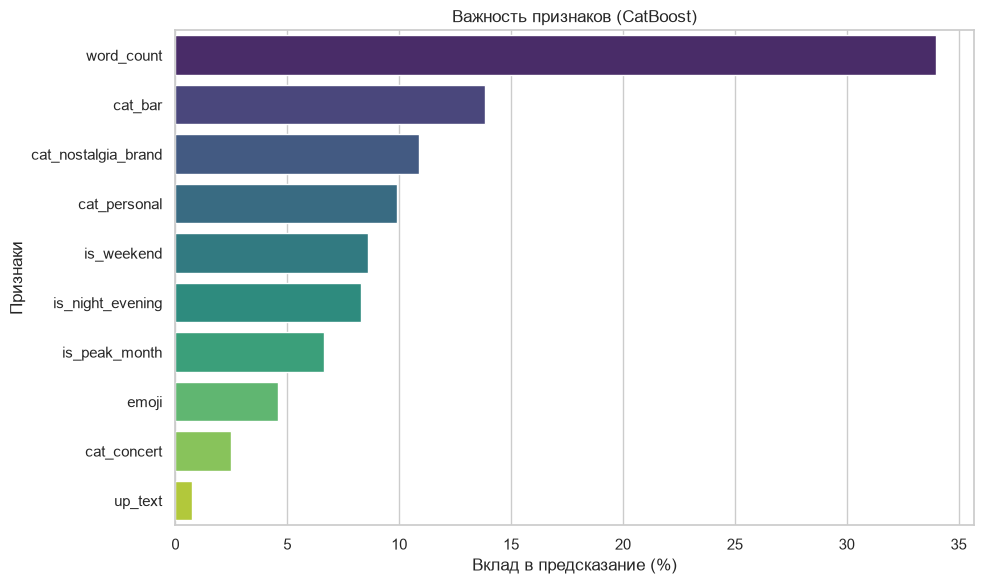

               Feature  Importance
3           word_count   33.989087
7              cat_bar   13.839754
8  cat_nostalgia_brand   10.877812
9         cat_personal    9.908523
0           is_weekend    8.604222
1     is_night_evening    8.276878
2        is_peak_month    6.640401
5                emoji    4.604236
6          cat_concert    2.498408
4              up_text    0.760679


In [28]:
# 1. Задаем фичи и таргет
features = [
    "is_weekend",
    "is_night_evening",
    "is_peak_month",
    "word_count",
    "up_text",
    "emoji",
    "cat_concert",
    "cat_bar",
    "cat_nostalgia_brand",
    "cat_personal",
]

X = df[features]
y = df["log_er_view"]

# 2. Обучаем CatBoost без вывода лишних логов обучения
model = CatBoostRegressor(
    iterations=200, depth=4, learning_rate=0.05, random_seed=42, verbose=0
)
model.fit(X, y)

# 3. Собираем важность признаков
df_imp = pd.DataFrame(
    {"Feature": features, "Importance": model.get_feature_importance()}
).sort_values(by="Importance", ascending=False)

# 4. Строим график
plt.figure(figsize=(10, 6))
sns.barplot(data=df_imp, x="Importance", y="Feature", palette="viridis")
plt.title("Важность признаков (CatBoost)")
plt.xlabel("Вклад в предсказание (%)")
plt.ylabel("Признаки")
plt.tight_layout()
plt.show()

# Вывод цифр
print(df_imp)

Итак, топ-3 признаков по версии CatBoost:
1. word_count (33.99%): Абсолютный лидер. Деревья решений отдали ему треть всей важности. Это связано с тем, что непрерывный признак дает модели множество точек для ветвления. CatBoost нашел конкретные пороги длины текста, которые делят посты на «проходные» и «глубокие».
2. cat_bar (13.84%): Из всех бинарных флагов тема бара — самая мощная по влиянию на модель. Это еще раз подтверждает причинно-следственный вывод: данная тема является главным фактором, ломающим метрики страницы.
3. cat_nostalgia_brand (10.88%): Тема бренда и музыки заняла третью строчку по важности.
При этом временные фичи (is_weekend — 8.60%, is_night_evening — 8.28%) плотно идут следом, подтверждая свой стабильный вклад. Капс (up_text — 0.76%) модель посчитала наименее важным нелинейным признаком, что логично — его влияние линейно давило на ER, но сложных скрытых связей с другими фичами он не имеет.

In [29]:
df.to_csv("zhukov_cleaned_data.csv", index=False, encoding="utf-8-sig")